<a href="https://colab.research.google.com/github/Milu2662/BI-PYMES-ML/blob/main/notebook/03_feature_engineering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BI-PYMES-ML — FEATURE ENGINEERING



In [1]:
!git clone https://github.com/Milu2662/BI-PYMES-ML.git /content/BI-PYMES-ML

Cloning into '/content/BI-PYMES-ML'...
remote: Enumerating objects: 42, done.
remote: Counting objects: 100% (42/42), done.
remote: Compressing objects: 100% (30/30), done.
remote: Total 42 (delta 11), reused 29 (delta 5), pack-reused 0 (from 0)
Receiving objects: 100% (42/42), 44.84 KiB | 7.47 MiB/s, done.
Resolving deltas: 100% (11/11), done.


In [2]:
from pathlib import Path
import sys
candidates=[Path("/content/BI-PYMES-ML"),Path.cwd()]
PROJECT_DIR=next((p for p in candidates if (p/"src").exists()),Path.cwd())
if not (PROJECT_DIR/"src").exists():
    raise FileNotFoundError("No se encontró src/. Ajusta PROJECT_DIR a la raíz del repositorio.")
sys.path.insert(0,str(PROJECT_DIR))
for d in ["data/raw","data/processed","data/experimental","results/figures","results/metrics"]:
    (PROJECT_DIR/d).mkdir(parents=True,exist_ok=True)
print("Proyecto:",PROJECT_DIR)

Proyecto: /content/BI-PYMES-ML


In [4]:
from google.colab import drive
from pathlib import Path
import shutil

# Conectar Google Drive
drive.mount('/content/drive')

# Archivo almacenado en Drive
source = Path(
    "/content/drive/MyDrive/BI-PYMES-ML/retail_lines.pkl"
)

# Destino dentro del proyecto
destination = PROJECT_DIR / "data/processed/retail_lines.pkl"

destination.parent.mkdir(parents=True, exist_ok=True)

if not source.exists():
    raise FileNotFoundError("No se encontró el archivo en Google Drive.")

shutil.copy2(source, destination)

print("Datos recuperados correctamente.")
print("Archivo:", destination)
print("Proyecto:",PROJECT_DIR)

Mounted at /content/drive
Datos recuperados correctamente.
Archivo: /content/BI-PYMES-ML/data/processed/retail_lines.pkl
Proyecto: /content/BI-PYMES-ML


## 3. Ingeniería de características
Agregamos las líneas de transacción a nivel de factura para generar variables comerciales.

In [5]:
import pandas as pd
from src.preprocessing import build_invoice_features
p=PROJECT_DIR/"data/processed/retail_lines.pkl"
if not p.exists(): raise FileNotFoundError("Ejecuta primero Notebook 01.")
df=pd.read_pickle(p); invoice=build_invoice_features(df)
print(invoice.shape); display(invoice.head()); display(invoice.describe(include="all").T)
invoice.to_pickle(PROJECT_DIR/"data/processed/invoice_features.pkl")
invoice.to_csv(PROJECT_DIR/"data/processed/invoice_features.csv",index=False)

(53628, 14)


,InvoiceNo,line_count,total_quantity,mean_quantity,mean_unit_price,total_revenue,revenue_abs,min_unit_price,max_unit_price,cancellation_line_share,invoice_date,customer_id,country,invoice_month
0,489434,8,166,20.750000,4.081250,505.30,505.30,1.25,6.95,0.0,2009-12-01 07:45:00,13085.0,United Kingdom,2009-12
1,489435,4,60,15.000000,2.625000,145.80,145.80,1.65,3.75,0.0,2009-12-01 07:46:00,13085.0,United Kingdom,2009-12
2,489436,19,193,10.157895,3.730526,630.33,630.33,1.25,8.50,0.0,2009-12-01 09:06:00,13078.0,United Kingdom,2009-12
3,489437,23,145,6.304348,3.628261,310.75,310.75,0.65,9.95,0.0,2009-12-01 09:08:00,15362.0,United Kingdom,2009-12
4,489438,17,826,48.588235,2.591176,2286.24,2286.24,0.98,6.40,0.0,2009-12-01 09:24:00,18102.0,United Kingdom,2009-12


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,53628,53628,489434,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
line_count,53628.0,NaN,NaN,NaN,19.903241,1.0,2.0,9.0,23.0,1350.0,41.252573
total_quantity,53628.0,NaN,NaN,NaN,197.81629,-87167.0,2.0,93.0,233.0,87167.0,1234.716062
mean_quantity,53628.0,NaN,NaN,NaN,12.120691,-80995.0,1.0,6.473684,13.4,80995.0,715.542993
mean_unit_price,53628.0,NaN,NaN,NaN,20.885174,-53594.36,1.770588,2.817773,4.33285,38970.0,532.401937
total_revenue,53628.0,NaN,NaN,NaN,359.648888,-168469.6,0.0,196.345,403.6525,168469.6,1654.829288
revenue_abs,53628.0,NaN,NaN,NaN,422.515956,0.0,30.2225,205.925,413.68,168469.6,1639.904462
min_unit_price,53628.0,NaN,NaN,NaN,18.74242,-53594.36,0.38,0.65,1.45,38970.0,532.207207
max_unit_price,53628.0,NaN,NaN,NaN,32.150206,-53594.36,2.95,7.95,12.75,38970.0,536.014335
cancellation_line_share,53628.0,NaN,NaN,NaN,0.154621,0.0,0.0,0.0,0.0,1.0,0.361546


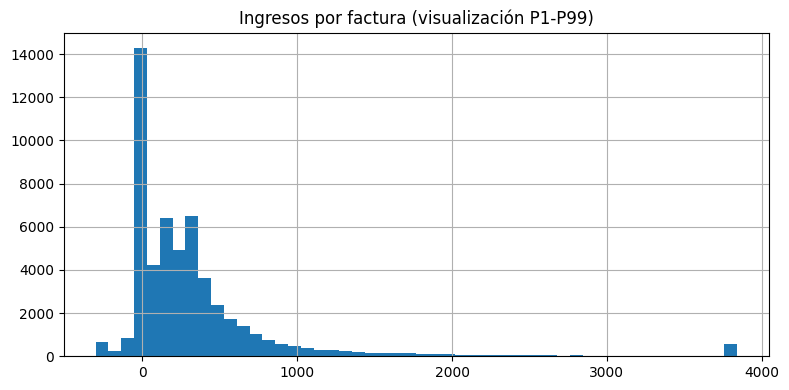

In [6]:
import matplotlib.pyplot as plt
x=invoice.total_revenue.clip(invoice.total_revenue.quantile(.01),invoice.total_revenue.quantile(.99))
plt.figure(figsize=(8,4)); x.hist(bins=50)
plt.title("Ingresos por factura (visualización P1-P99)")
plt.tight_layout(); plt.savefig(PROJECT_DIR/"results/figures/invoice_revenue_distribution.png",dpi=160); plt.show()

In [16]:
import pandas as pd
import numpy as np

# 1. VALIDAR Y PREPARAR EL DATAFRAME

if "invoice" not in globals():
    raise NameError(
        "No existe el DataFrame 'invoice'. "
        "Ejecuta primero las celdas del Notebook 03."
    )

invoice_features = invoice.copy()

print("AUDITORÍA DE FACTURAS - BI-PYMES-ML")
print("=" * 70)

print(f"Total de facturas: {len(invoice_features):,}")
print(f"Total de variables: {len(invoice_features.columns)}")

AUDITORÍA DE FACTURAS - BI-PYMES-ML
Total de facturas: 53,628
Total de variables: 14


In [14]:
# 2. TOP 15 FACTURAS POR INGRESOS ABSOLUTOS

print("\n1. TOP 15 FACTURAS POR INGRESOS ABSOLUTOS")

top_revenue = invoice_features.nlargest(
    15, "revenue_abs"
)

display(
    top_revenue[
        [
            "InvoiceNo",
            "line_count",
            "total_quantity",
            "mean_unit_price",
            "total_revenue",
            "revenue_abs",
            "cancellation_line_share",
            "customer_id"
        ]
    ]
)


1. TOP 15 FACTURAS POR INGRESOS ABSOLUTOS


,InvoiceNo,line_count,total_quantity,mean_unit_price,total_revenue,revenue_abs,cancellation_line_share,customer_id
45294,581483,1,80995,2.080000,168469.60,168469.60,0.0,16446.0
53623,C581484,1,-80995,2.080000,-168469.60,168469.60,1.0,16446.0
25572,541431,1,74215,1.040000,77183.60,77183.60,0.0,12346.0
50238,C541433,1,-74215,1.040000,-77183.60,77183.60,1.0,12346.0
45330,A506401,1,1,-53594.360000,-53594.36,53594.36,0.0,NaN
42045,574941,101,14149,4.939505,52940.94,52940.94,0.0,NaN
42737,576365,99,13956,4.742525,50653.91,50653.91,0.0,NaN
21730,533027,111,13387,5.096306,49844.99,49844.99,0.0,NaN
21034,531516,115,12410,5.687913,45332.97,45332.97,0.0,NaN
2063,493819,94,25018,2.427553,44051.60,44051.60,0.0,14156.0


In [17]:
# 3. FACTURAS CON CANTIDADES NEGATIVAS

print("\n2. FACTURAS CON CANTIDADES NEGATIVAS")

negative_quantity = invoice_features[
    invoice_features["total_quantity"] < 0
].copy()

print(
    f"Facturas con cantidad total negativa: "
    f"{len(negative_quantity):,}"
)

display(
    negative_quantity.head(15)[
        [
            "InvoiceNo",
            "line_count",
            "total_quantity",
            "mean_quantity",
            "mean_unit_price",
            "total_revenue",
            "cancellation_line_share"
        ]
    ]
)


2. FACTURAS CON CANTIDADES NEGATIVAS
Facturas con cantidad total negativa: 11,684


,InvoiceNo,line_count,total_quantity,mean_quantity,mean_unit_price,total_revenue,cancellation_line_share
19,489463,1,-240,-240.0,0.0,0.0,0.0
20,489464,1,-96,-96.0,0.0,0.0,0.0
22,489467,1,-192,-192.0,0.0,0.0,0.0
29,489521,1,-50,-50.0,0.0,0.0,0.0
113,489655,1,-44,-44.0,0.0,0.0,0.0
118,489660,1,-1043,-1043.0,0.0,0.0,0.0
121,489663,1,-117,-117.0,0.0,0.0,0.0
184,489806,1,-770,-770.0,0.0,0.0,0.0
197,489820,1,-720,-720.0,0.0,0.0,0.0
198,489821,1,-240,-240.0,0.0,0.0,0.0


In [18]:
# 4. FACTURAS CON PRECIO PROMEDIO NEGATIVO

print("\n3. FACTURAS CON PRECIO PROMEDIO NEGATIVO")

negative_price = invoice_features[
    invoice_features["mean_unit_price"] < 0
].copy()

print(
    f"Facturas con precio promedio negativo: "
    f"{len(negative_price):,}"
)

display(
    negative_price[
        [
            "InvoiceNo",
            "line_count",
            "total_quantity",
            "mean_unit_price",
            "total_revenue",
            "min_unit_price",
            "max_unit_price"
        ]
    ].head(15)
)


3. FACTURAS CON PRECIO PROMEDIO NEGATIVO
Facturas con precio promedio negativo: 5


,InvoiceNo,line_count,total_quantity,mean_unit_price,total_revenue,min_unit_price,max_unit_price
45330,A506401,1,1,-53594.36,-53594.36,-53594.36,-53594.36
45331,A516228,1,1,-44031.79,-44031.79,-44031.79,-44031.79
45332,A528059,1,1,-38925.87,-38925.87,-38925.87,-38925.87
45334,A563186,1,1,-11062.06,-11062.06,-11062.06,-11062.06
45335,A563187,1,1,-11062.06,-11062.06,-11062.06,-11062.06


In [20]:
# 5. IDENTIFICAR FACTURAS DE CANCELACIÓN

invoice_features["is_cancellation_invoice"] = (
    invoice_features["InvoiceNo"]
    .astype(str)
    .str.strip()
    .str.upper()
    .str.startswith("C")
)

print("\n4. CLASIFICACIÓN DE FACTURAS")

cancellation_summary = (
    invoice_features["is_cancellation_invoice"]
    .value_counts()
    .rename(index={
        True: "Cancelación",
        False: "Factura regular"
    })
    .to_frame("Cantidad")
)

cancellation_summary["Porcentaje"] = (
    cancellation_summary["Cantidad"]
    / len(invoice_features) * 100
)

display(cancellation_summary)


4. CLASIFICACIÓN DE FACTURAS


,Cantidad,Porcentaje
is_cancellation_invoice,,
Factura regular,45336,84.537928
Cancelación,8292,15.462072


In [21]:
# 6. COMPARAR CANCELACIONES Y FACTURAS REGULARES

print("\n5. COMPARACIÓN DE COMPORTAMIENTO TRANSACCIONAL")

comparison = (
    invoice_features
    .groupby("is_cancellation_invoice")
    .agg(
        invoices=("InvoiceNo", "count"),
        mean_revenue=("total_revenue", "mean"),
        median_revenue=("total_revenue", "median"),
        mean_quantity=("total_quantity", "mean"),
        mean_price=("mean_unit_price", "mean"),
        mean_lines=("line_count", "mean"),
        mean_cancellation_share=(
            "cancellation_line_share", "mean"
        )
    )
    .rename(index={
        True: "Cancelaciones",
        False: "Facturas regulares"
    })
)

display(comparison)


5. COMPARACIÓN DE COMPORTAMIENTO TRANSACCIONAL


,invoices,mean_revenue,median_revenue,mean_quantity,mean_price,mean_lines,mean_cancellation_share
is_cancellation_invoice,,,,,,,
Facturas regulares,45336,459.103547,263.54,244.827157,7.924398,23.113574,0.0
Cancelaciones,8292,-184.113345,-17.40,-59.212735,91.747421,2.350941,1.0


In [22]:
# 7. RESUMEN DE HALLAZGOS

print("\n6. RESUMEN DE LA AUDITORÍA")

summary = pd.DataFrame({
    "Indicador": [
        "Total de facturas",
        "Facturas de cancelación",
        "Facturas regulares",
        "Facturas con cantidad negativa",
        "Facturas con precio promedio negativo",
        "Facturas con ingresos negativos",
        "Facturas con ingresos iguales a cero",
        "Facturas con líneas de cancelación"
    ],
    "Cantidad": [
        len(invoice_features),
        invoice_features["is_cancellation_invoice"].sum(),
        (~invoice_features["is_cancellation_invoice"]).sum(),
        (invoice_features["total_quantity"] < 0).sum(),
        (invoice_features["mean_unit_price"] < 0).sum(),
        (invoice_features["total_revenue"] < 0).sum(),
        (invoice_features["total_revenue"] == 0).sum(),
        (invoice_features["cancellation_line_share"] > 0).sum()
    ]
})

summary["Porcentaje"] = (
    summary["Cantidad"] / len(invoice_features) * 100
)

display(summary.round(3))


6. RESUMEN DE LA AUDITORÍA


,Indicador,Cantidad,Porcentaje
0,Total de facturas,53628,100.000
1,Facturas de cancelación,8292,15.462
2,Facturas regulares,45336,84.538
3,Facturas con cantidad negativa,11684,21.787
4,Facturas con precio promedio negativo,5,0.009
5,Facturas con ingresos negativos,8296,15.470
6,Facturas con ingresos iguales a cero,5254,9.797
7,Facturas con líneas de cancelación,8292,15.462


In [23]:
# 8. GUARDAR RESULTADOS DE AUDITORÍA

output_dir = PROJECT_DIR / "results/metrics"
output_dir.mkdir(parents=True, exist_ok=True)

summary.to_csv(
    output_dir / "invoice_audit_summary.csv",
    index=False
)

comparison.to_csv(
    output_dir / "invoice_cancellation_comparison.csv"
)

top_revenue.to_csv(
    output_dir / "top_15_extreme_invoices.csv",
    index=False
)

print("\nAuditoría finalizada correctamente.")
print("Resultados guardados en:", output_dir)


Auditoría finalizada correctamente.
Resultados guardados en: /content/BI-PYMES-ML/results/metrics
